In [8]:
import random
from dataclasses import dataclass, field
from typing import Any, List, Tuple, Optional, Dict, Callable

random.seed(42)

@dataclass(frozen=True)
class Step:
    action: Any
    state: Any
    cost: float

class SearchProblem:

    def start_state(self) -> Any:
        raise NotImplementedError

    def successors(self, state: Any) -> List[Step]:
        raise NotImplementedError
    
    def is_end(self, state: Any) -> bool:
        raise NotImplementedError

@dataclass
class Solution:
    steps: List[Step]
    cost: float = field(init=False)

    def __post_init__(self):
        self.cost = sum(step.cost for step in self.steps)

In [30]:
# Run Uniform Cost Search (UCS) on a search problem.

import heapq

class PriorityQueue:
    def __init__(self):
        self.DONE = -100000.0
        self.heap = []
        self.priorities: Dict[Any, float] = {}

    def update(self, state: Any, new_priority: float) -> bool:
        old_priority = self.priorities.get(state)
        if old_priority is None or new_priority < old_priority:
            self.priorities[state] = new_priority
            heapq.heappush(self.heap, (new_priority, state)) # priority first - ordered by priority instead of state!
            return True
        return False

    def remove_min(self) -> Tuple[Optional[Any], Optional[float]]:
        while len(self.heap) > 0:
            priority, state = heapq.heappop(self.heap)
            if self.priorities.get(state) == self.DONE: # if this state has already been visited, pop up next item
                continue
            self.priorities[state] = self.DONE
            return state, priority
        return None, None

# Records parent state and action for path reconstruction
@dataclass(frozen=True)
class BackPointer:
    prev_state: Any
    action: Any
    cost: float

def uniform_cost_search(problem: SearchProblem) -> Tuple[Optional[Solution], int]:
    frontier = PriorityQueue()
    backpointers: Dict[Any, BackPointer] = {} # store parent node for each state
    num_explored = 0
    start_state = problem.start_state()
    frontier.update(start_state, 0)
    while True:
        state, past_cost = frontier.remove_min()
        num_explored += 1
        if state is None or past_cost is None: # queue is empty, no solution to the end state is found
            return None, num_explored
        if problem.is_end(state):
            # reconstruct the paths from the start state
            current = state
            steps = []
            while current != start_state:
                prev = backpointers[current]
                steps.insert(0, Step(prev.action, current, prev.cost))
                current = prev.prev_state
            return Solution(steps), num_explored
                
        for successor in problem.successors(state):
            if frontier.update(successor.state, past_cost + successor.cost):
                backpointers[successor.state] = BackPointer(state, successor.action, successor.cost)
    return None, num_explored



In [31]:
# Specific Search Problem Implementations & Graph Visualizer
from graphviz import Digraph

class DiamondSearchProblem(SearchProblem):
    """Graph search problem with cycles (Diamond shape)."""
    def __init__(self):
        self.graph = {
            "A": {"B": 1, "C": 100},
            "B": {"A": 1, "C": 1, "D": 100},
            "C": {"A": 100, "B": 1, "D": 1},
            "D": {"B": 100, "C": 1},
        }

    def start_state(self) -> str:
        return "A"

    def successors(self, state: str) -> List[Step]:
        return [Step(action=nbr, cost=c, state=nbr) for nbr, c in self.graph[state].items()]

    def is_end(self, state: str) -> bool:
        return state == "D"

class GridSearchProblem(SearchProblem):
    """Grid navigation problem with obstacles ('#')."""
    def __init__(self, *rows: str):
        self.rows = [r.replace(" ", "") for r in rows]

    def start_state(self) -> Tuple[int, int]:
        for r in range(self.num_rows):
            for c in range(self.num_cols):
                if self.rows[r][c] == "S":
                    return (r, c)
        raise ValueError("No start state found")

    def is_valid(self, state: Tuple[int, int]) -> bool:
        r, c = state
        return 0 <= r < self.num_rows and 0 <= c < self.num_cols and self.rows[r][c] != "#"

    def successors(self, state: Tuple[int, int]) -> List[Step]:
        r, c = state
        succs = []
        directions = [("down", r+1, c), ("up", r-1, c), ("right", r, c+1), ("left", r, c-1)]
        for act, nr, nc in directions:
            if self.is_valid((nr, nc)):
                succs.append(Step(action=act, cost=1.0, state=(nr, nc)))
        return succs

    def is_end(self, state: Tuple[int, int]) -> bool:
        return self.rows[state[0]][state[1]] == "E"

    @property
    def num_rows(self) -> int:
        return len(self.rows)

    @property
    def num_cols(self) -> int:
        return len(self.rows[0])

class LineSearchProblem(SearchProblem):
    """1D Line search problem ranging from -2 to 2."""
    def start_state(self) -> int:
        return 0

    def successors(self, state: int) -> List[Step]:
        succs = []
        if state >= -2:
            succs.append(Step(action="left", cost=1.0, state=state - 1))
        if state <= 2:
            succs.append(Step(action="right", cost=1.0, state=state + 1))
        return succs

    def is_end(self, state: int) -> bool:
        return state == 2

def draw_graph(problem: SearchProblem) -> Digraph:
    """Traverse state space and generate Graphviz representation."""
    dot = Digraph()
    visited = set()

    def recurse(state: Any):
        if state in visited:
            return
        visited.add(state)
        if problem.is_end(state):
            dot.node(str(state), shape="doublecircle")
        else:
            dot.node(str(state), shape="circle")
            for step in problem.successors(state):
                dot.edge(str(state), str(step.state), label=f"{step.action}:{step.cost}")
                recurse(step.state)

    recurse(problem.start_state())
    return dot



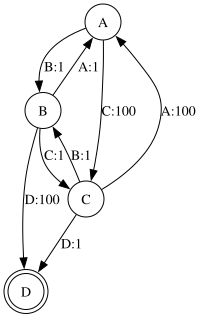

UCS on DiamondProblem -> Total Cost:3, Explored:4
Steps: [Step(action='B', state='B', cost=1), Step(action='C', state='C', cost=1), Step(action='D', state='D', cost=1)]


In [32]:
# Test UCS 

diamond_p = DiamondSearchProblem()
display(draw_graph(diamond_p))

sol, explored = uniform_cost_search(diamond_p)
print(f"UCS on DiamondProblem -> Total Cost:{sol.cost}, Explored:{explored}")
print("Steps:", sol.steps)

In [33]:
# A* search

from typing import Any, List

Heuristic = Callable[[Any], float]

# Wrapper that modifies action costs using heuristic: Cost'(s,a) = Cost(s,a) + h(s') - h(s).
class ModifiedSearchProblem(SearchProblem):

    def __init__(self, problem: SearchProblem, heuristic: Heuristic):
        self.problem = problem
        self.heuristic = heuristic

    def start_state(self) -> Any:
        return self.problem.start_state()

    def is_end(self, state: Any) -> bool:
        return self.problem.is_end(state)

    def successors(self, state: Any) -> List[Step]:
        steps = []
        for successor in self.problem.successors(state):
            new_cost = successor.cost + self.heuristic(successor.state) - self.heuristic(state)
            steps.append(Step(successor.action, successor.state, new_cost))
        return steps
        
def astar_search(problem: SearchProblem, heuristic: Heuristic) -> Tuple[Optional[Solution], int]:
    modified_problem = ModifiedSearchProblem(problem, heuristic)
    solution, num_explored = uniform_cost_search(modified_problem)
    if solution is None:
        return solution, num_explored
    steps = []
    state = modified_problem.start_state()
    for step in solution.steps:
        original_cost = step.cost - heuristic(step.state) + heuristic(state)
        steps.append(Step(step.action, step.state, original_cost))
        state = step.state
    return Solution(steps), num_explored

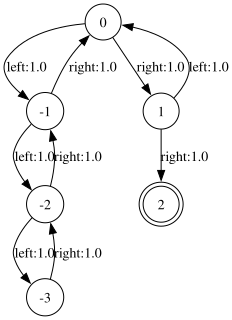

UCS on Line -> Cost:2.0, Explored:5
A* on Line  -> Cost:2.0, Explored:3


In [34]:
# Test UCS vs A* - Line Search Problem

line_p = LineSearchProblem()
display(draw_graph(line_p))

# Heuristic: distance to end state (state 2)
def line_heuristic(state: int) -> float:
    return 2 - state

ucs_sol, ucs_exp = uniform_cost_search(line_p)
astar_sol, astar_exp = astar_search(line_p, line_heuristic)

print(f"UCS on Line -> Cost:{ucs_sol.cost}, Explored:{ucs_exp}")
print(f"A* on Line  -> Cost:{astar_sol.cost}, Explored:{astar_exp}")

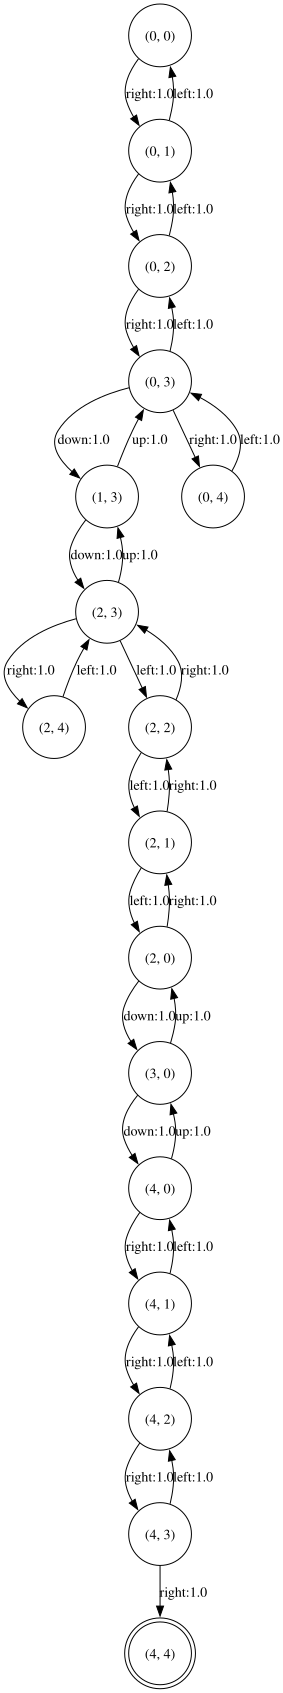

Grid Search (UCS) -> Explored:17, Cost:14.0
Grid Search (A*)  -> Explored:17, Cost:14.0


In [35]:
# Relaxation - Manhattan Distance for Grid

grid_p = GridSearchProblem(
    " S . . . .",
    " # # # . #",
    " . . . . .",
    " . # # # #",
    " . . . . E",
)
display(draw_graph(grid_p))

# Relaxed problem: remove all obstacles (#) -> Manhattan Distance
def manhattan_heuristic(state: Tuple[int, int]) -> float:
    goal_r, goal_c = grid_p.num_rows - 1, grid_p.num_cols - 1
    r, c = state
    return float(abs(goal_r - r) + abs(goal_c - c))

ucs_sol, ucs_exp = uniform_cost_search(grid_p)
astar_sol, astar_exp = astar_search(grid_p, manhattan_heuristic)

print(f"Grid Search (UCS) -> Explored:{ucs_exp}, Cost:{ucs_sol.cost}")
print(f"Grid Search (A*)  -> Explored:{astar_exp}, Cost:{astar_sol.cost}")